# Tentativo 14 · 1. Preparazione del dataset (versione semplice)

**Obiettivo**: un dataset di articoli di testate **politiche**, ognuna con il suo livello NewsGuard 2026, diviso in
5 fold. Le regole sono quattro:

1. teniamo **solo le testate politiche**, fin dall'inizio;
2. **puliamo** articoli e testi;
3. troviamo i **gruppi** di testate parenti (stessa rete, stesso proprietario): un gruppo sta **tutto in un fold**;
4. teniamo le testate con **almeno 10 articoli**. Tutte le testate sono una volta nel test e quattro volte nel training.

In [1]:
N_JOBS = 32       # processi in parallelo
TESTATE = 0       # 0 = tutte; un numero = prova veloce su quel numero di testate a caso

In [2]:
import hashlib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold

import funzioni as F                     # le funzioni lunghe (lingua, copie, reti), prese dai tentativi precedenti

warnings.filterwarnings("ignore")
DATI = F.DATI                             # la cartella unica dei dati (Dataset/ nella radice del repo)
GIRI = [DATI / "scraping" / "NuovoScraping_ottobre", DATI / "scraping" / "NuovoScraping_giro3"]     # lo scraping di ottobre 2026
OUT = Path("Results/dataset") / ("prova" if TESTATE else "")             # grafici e tabelle
DATASET = F.DATASET / ("prova" if TESTATE else ""); DATASET.mkdir(parents=True, exist_ok=True)   # il dataset
GRAFICI = OUT / "grafici"; GRAFICI.mkdir(parents=True, exist_ok=True)

# colori: blu = si tiene, arancio = si toglie; livelli NewsGuard dal rosso (l1, inaffidabile) al blu (l5)
BLU, ARANCIO, VERDE, GRIGIO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
    "patch.force_edgecolor": True, "patch.edgecolor": "#fcfcfb", "patch.linewidth": 0.6,
})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 100)

passi = []
def passo(nome, df):
    """Annota e stampa quanti articoli e testate restano dopo un passo."""
    tolti = passi[-1]["articoli"] - len(df) if passi else 0
    passi.append({"passo": nome, "articoli": len(df), "testate": df.domain.nunique()})
    print(f"→ restano {len(df):,} articoli di {df.domain.nunique():,} testate (tolti {tolti:,} articoli)")

def mostra(nome, griglia="y"):
    """Mostra il grafico (griglia solo sull'asse dei valori) e lo salva anche in PNG, per le slide."""
    for a in plt.gcf().axes:
        a.grid(False); a.grid(axis=griglia)
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

def barre(serie, titolo, nome, figsize=(8, 2.6)):
    """Barre orizzontali con il numero scritto in fondo a ogni barra."""
    serie = serie[::-1]
    plt.figure(figsize=figsize); plt.barh(serie.index, serie, color=BLU)
    for y, v in enumerate(serie):
        plt.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
    plt.title(titolo); plt.gca().xaxis.set_major_formatter("{x:,.0f}"); mostra(nome, "x")

## 1. Da dove partiamo: le testate politiche

**NewsGuard 2026** dà un punteggio a migliaia di testate e indica i loro **argomenti**. A ottobre 2026 abbiamo fatto lo
scraping di una parte di queste: fino a 200 articoli per testata. Teniamo subito **solo le testate politiche**: quelle
che per NewsGuard hanno un solo argomento, "Political news or commentary".

In [3]:
# 1.1 le etichette NewsGuard e com'è andato lo scraping (un file di stato per testata)
n26, n22 = F.leggi_newsguard(DATI / "etichette" / "newsguard_2026.csv"), F.leggi_newsguard(DATI / "etichette" / "newsguard_2022.csv")
stati = pd.concat([F.leggi_stati([g]) for g in GIRI], ignore_index=True)
stati["argomenti"] = stati.dominio.map(n26.Topics).fillna("")
solo_politica = stati.argomenti.str.split(",").map(lambda x: [a.strip() for a in x if a.strip()] == [F.POLITICA])
stati["politica"] = solo_politica & stati.dominio.map(n26.Score).notna()      # un solo argomento, la politica, e un punteggio
stati["raggiunta"] = ~stati.esito.str.startswith("homepage")
if TESTATE:                                   # prova veloce: poche testate politiche a caso
    stati = stati[stati.dominio.isin(stati.dominio[stati.politica].sample(TESTATE, random_state=F.SEED))]

In [4]:
# 1.2 gli argomenti più frequenti tra le testate dello scraping (le testate con più argomenti restano fuori)
stati.argomenti.str.replace(",", " +").replace("", "(nessuno)").value_counts().head(8).rename("testate").to_frame()

,testate
argomenti,
Political news or commentary,1293
Political news or commentary +Local News,1255
Health or medical information +Political news or commentary +Conspiracy theories or hoaxes,589
Political news or commentary +General News,441
Political news or commentary +Conspiracy theories or hoaxes,238
Political news or commentary +Business or Personal Finance,176
Conspiracy theories or hoaxes +Political news or commentary,122
Local News,117


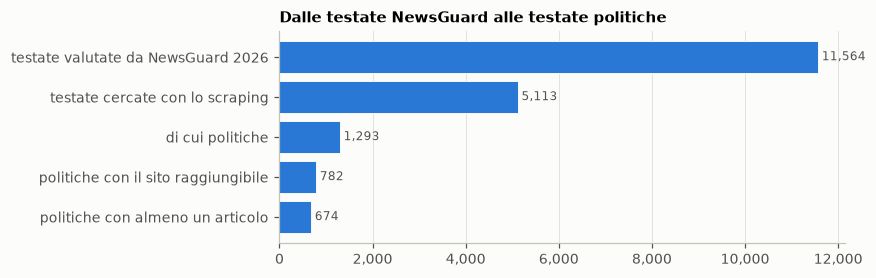

→ restano 86,225 articoli di 674 testate (tolti 0 articoli)


,domain,titolo,data,parole,text
68246,thecollegefix.com,"Due to ‘federal attacks,’ George Washington U. student gov. creates ‘LGTBQ+ Caucus’ | The Colleg...",2026-10-11,413,"Due to “ongoing federal attacks” against the LGBTQ+ community, the Student Gover …"
69143,thedailybeat.org,Forecasters Fear Flooding Could Escalate Quickly,2026-06-25,894,Millions of Americans are bracing for heavy rain that could turn the Great Plain …
20008,dworkinsubstack.com,"First-Ever Impeachment Articles Filed Against A Chief Justice, AOC Forces Trump’s EPA On Record,...",2026-05-26,76,"First-Ever Impeachment Articles Filed Against A Chief Justice, AOC Forces Trump’ …"


In [5]:
# 1.3 i testi delle testate politiche: una riga per articolo
politiche = stati.dominio[stati.politica]
grezzo = F.leggi_scraping(GIRI, politiche).rename(columns={"dominio": "domain", "testo": "text"})

barre(pd.Series({"testate valutate da NewsGuard 2026": n26.Score.notna().sum(),
                 "testate cercate con lo scraping": len(stati),
                 "di cui politiche": stati.politica.sum(),
                 "politiche con il sito raggiungibile": (stati.politica & stati.raggiunta).sum(),
                 "politiche con almeno un articolo": grezzo.domain.nunique()}), "Dalle testate NewsGuard alle testate politiche", "1_testate")
passo("1.3 testi delle testate politiche", grezzo)
grezzo[["domain", "titolo", "data", "parole", "text"]].sample(3, random_state=1).assign(text=lambda d: d.text.str[:80] + " …")

## 2. La pulizia

Prima togliamo gli **articoli** che non servono (troppo corti, doppi, non in inglese, troppo vecchi), poi puliamo il
**testo**: le parti che il sito ripete sempre uguali (firme, inviti a donare, titolo e data in testa, link) non dicono
nulla sull'articolo e fanno solo riconoscere il sito.

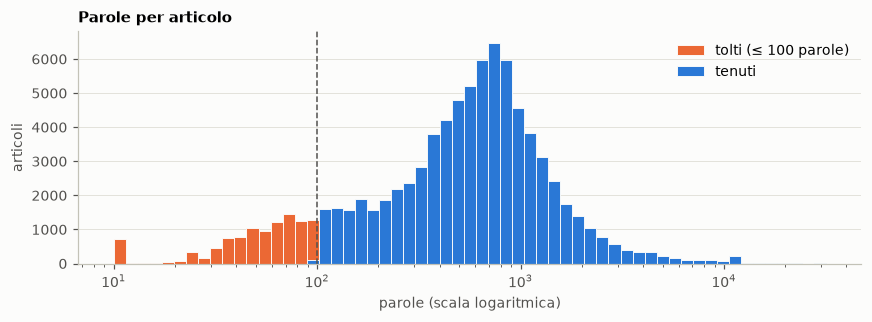

→ restano 75,647 articoli di 663 testate (tolti 10,578 articoli)


In [6]:
# 2.1 via gli articoli corti (≤ 100 parole): pagine di servizio, didascalie, brevi
bins = np.logspace(1, 4.5, 60)
plt.hist(grezzo.parole[grezzo.parole <= 100].clip(lower=10), bins, color=ARANCIO, label="tolti (≤ 100 parole)")
plt.hist(grezzo.parole[grezzo.parole > 100], bins, color=BLU, label="tenuti")
plt.xscale("log"); plt.axvline(100, color=GRIGIO, ls="--", lw=1)
plt.title("Parole per articolo"); plt.xlabel("parole (scala logaritmica)"); plt.ylabel("articoli"); plt.legend()
mostra("2_parole")

art = grezzo[grezzo.parole > 100]
passo("2.1 più di 100 parole", art)

In [7]:
# 2.2 via i doppioni nella stessa testata: stesso URL o stesso testo
art = art.drop_duplicates(["domain", "url"]).drop_duplicates(["domain", "text"])
passo("2.2 senza stesso URL o stesso testo", art)

→ restano 75,647 articoli di 663 testate (tolti 0 articoli)


In [8]:
# 2.3 solo inglese (riconoscimento automatico della lingua sulle prime 400 parole)
art = art.assign(lingua=Parallel(n_jobs=N_JOBS, batch_size=200)(delayed(F.lingua)(t) for t in art.text))
display(art.lingua.value_counts().head(6).rename("articoli").to_frame().T)
art = art[art.lingua == "en"].reset_index(drop=True).rename_axis("article_id").reset_index()   # da qui ogni articolo ha un numero
base = art.copy()                     # tutti gli articoli in inglese: servono per le frasi ripetute (2.6) e per i gruppi (3)
passo("2.3 solo inglese", art)

lingua,en,de,fr,it,ru,vi
articoli,61113,7472,4250,1405,739,400


→ restano 61,113 articoli di 571 testate (tolti 14,534 articoli)


In [9]:
# 2.4 lo stesso testo due volte nella stessa testata, anche con maiuscole o punteggiatura diverse: si tiene il più vecchio
art["data"] = pd.to_datetime(art.data, errors="coerce")
art["norm"] = art.text.map(F.normalizza)                         # minuscole, solo lettere e cifre, spazi singoli
art["impronta"] = art.norm.map(lambda s: hashlib.md5(s.encode()).hexdigest())
art = art.sort_values("data").drop_duplicates(["domain", "impronta"]).sort_index()
inglese = art.copy()                  # gli articoli in inglese di ogni data: qui dentro cerchiamo le copie tra testate (3.1)
passo("2.4 senza copie identiche nella testata", art)

→ restano 61,099 articoli di 571 testate (tolti 14 articoli)


In [10]:
# 2.5 solo articoli dal 2025: il periodo delle etichette NewsGuard 2026
anno = art.data.dt.year
per_anno = anno[anno >= 2015].astype(int).value_counts().sort_index()
display(pd.concat([pd.Series({"senza data": anno.isna().sum(), "prima del 2015": (anno < 2015).sum()}), per_anno]).rename("articoli").to_frame().T)
art = art[art.data >= "2025-01-01"]
passo("2.5 pubblicati dal 2025", art)

,senza data,prima del 2015,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
articoli,1,2563,174,438,612,505,991,1402,1268,2020,1884,2594,4358,42289


→ restano 46,647 articoli di 534 testate (tolti 14,452 articoli)


In [11]:
# 2.6 frasi che la stessa testata ripete in almeno 3 articoli: firme, inviti a donare o iscriversi, piè di pagina
tutti = base[["domain", "text"]].assign(norm=base.text.map(F.normalizza)).drop_duplicates(["domain", "norm"])
parole_prima = art.text.str.split().str.len().sum()
testi, esempi = F.togli_frasi_ripetute(art, tutti)            # le ripetizioni si contano su tutti gli articoli della testata
art = art.assign(text=testi)
print(f"parole tolte: {1 - art.text.str.split().str.len().sum() / parole_prima:.1%}")
pd.DataFrame(esempi, columns=["articoli", "testata", "frase ripetuta (esempio)"]).set_index("testata")

parole tolte: 5.5%


,articoli,frase ripetuta (esempio)
testata,,
truthout.org,200,we lost 15 percent of our readership overnight
truth-out.org,200,we lost 15 percent of our readership overnight
thewellnews.com,200,we re proud to make our journalism accessible to everyone but producing high quality journalism ...
spiked-online.com,200,support spiked and get unlimited access
spencerfernando.com,200,spencer fernando s writing is now on substack
sarahpalin.com,200,opinion the author s opinion does not necessarily reflect sarah palin s view
propatriotnews.com,200,the pro patriot news homepage has 60 new headlines every 24 hours click here to see it
prodesantisnews.com,200,the pro desantis news homepage has 60 new headlines every 24 hours click here to see it
pressprogress.ca,200,we re an award winning non profit news organization that covers topics like social and economic ...


In [12]:
# 2.7 titolo e data ripetuti all'inizio del testo
prima = art.text
esiti = [F.togli_cornice(t, ti) for t, ti in zip(art.text, art.titolo.fillna(""))]
art = art.assign(text=[e[0] for e in esiti])
print(f"titolo tolto: {sum(e[1] for e in esiti):,} articoli; data tolta: {sum(e[2] for e in esiti):,} articoli\n")

i = ([i for i, e in zip(art.index, esiti) if e[1] and e[2]] or [i for i, e in zip(art.index, esiti) if e[1]])[0]   # un esempio
print("PRIMA:", prima[i][:230].replace("\n", " ⏎ "), "…")
print("DOPO: ", art.text[i][:150].replace("\n", " ⏎ "), "…")

titolo tolto: 11,157 articoli; data tolta: 162 articoli

PRIMA: HJR326 Alabama 2026 Session ⏎ Updated Apr 18, 2026 ⏎ - Recognizing the need for a north-south transportation route in East Alabama ⏎ - Recognizing the need for a north-south transportation route in East Alabama. ⏎ Waggoner Concur In and A …
DOPO:  Recognizing the need for a north-south transportation route in East Alabama ⏎ - Recognizing the need for a north-south transportation route in East Alab …


In [13]:
# 2.8 link, firme dei tweet incorporati e scritte dei post incorporati ("View this post on Instagram")
prima = art.text
art = art.assign(text=art.text.map(F.togli_incorporati))
print(f"articoli toccati: {(art.text != prima).sum():,}; caratteri tolti: {1 - art.text.str.len().sum() / prima.str.len().sum():.2%}")

esempi, cambiati = [], art[art.text != prima].drop_duplicates("domain")        # una testata per esempio
for i in cambiati.sample(min(6, len(cambiati)), random_state=3).index:
    riga = [r for r in prima[i].split("\n") if r not in art.text[i]][0]
    esempi.append((art.domain[i], (F.LINK.findall(riga) or [riga])[0][:90]))     # il link, oppure la riga intera
pd.DataFrame(esempi, columns=["testata", "tolto (esempio)"]).set_index("testata")

articoli toccati: 7,585; caratteri tolti: 0.39%


,tolto (esempio)
testata,
therecorddaily.com,pic.twitter.com/xnJMZ18DZn
annatimes.com,https://creaxene.ai.
rightwinginsider.com,"— Master Thought (@MasterThousmg) October 10, 2026"
realnewsfeed.com,"— FBI Director Kash Patel (@FBIDirectorKash) October 23, 2026"
middleamericanews.com,https://t.co/eckH0z3Ids
idahotribune.org,https://www.cdc.gov/west-nile-virus/data-maps/current-year-data.html


In [14]:
# 2.9 articoli quasi uguali nella stessa testata (aggiornamenti dello stesso pezzo): si tiene il più vecchio
art["norm"] = art.text.map(F.normalizza)
art, n = F.togli_doppioni_in_testata(art.reset_index(drop=True), 0.5, N_JOBS)
passo("2.9 senza quasi doppioni nella testata", art)

→ restano 46,153 articoli di 534 testate (tolti 494 articoli)


In [15]:
# 2.10 dopo la pulizia devono restare almeno 100 parole
art = art[art.text.str.split().str.len() >= 100]
passo("2.10 almeno 100 parole dopo la pulizia", art)

→ restano 43,728 articoli di 532 testate (tolti 2,425 articoli)


## 3. I gruppi di testate parenti

Alcune testate sono **parenti**: si copiano gli articoli, sono siti fatti con lo stesso modello, hanno lo stesso
proprietario. Se una sta nel training e l'altra nel test, il modello riconosce la famiglia invece dell'affidabilità.
Due testate sono parenti se:

- **si copiano articoli** (testi quasi uguali), oppure
- hanno **le stesse tracce nelle pagine** (stessi codici pubblicitari o di statistiche, stesso titolare della privacy
  policy, stesso dominio, stessi autori), oppure
- per NewsGuard hanno **lo stesso proprietario** (Owner) o **lo stesso Parent Domain**.

Un **gruppo** = testate parenti, anche indirettamente (A parente di B e B di C: A, B e C nello stesso gruppo).

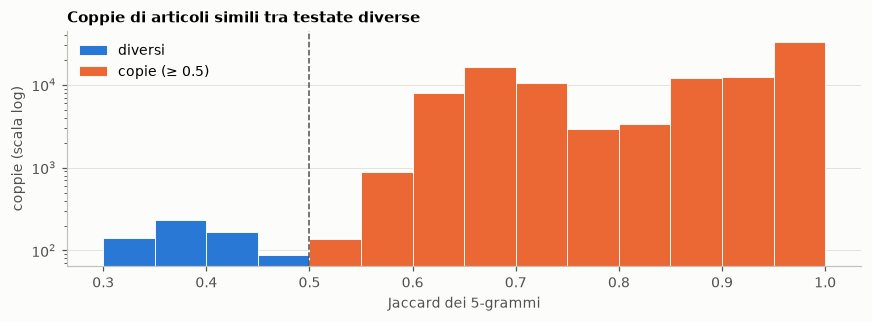

coppie di copie: 136,959; testate coinvolte: 319


In [16]:
# 3.1 articoli copiati tra testate diverse: somiglianza (Jaccard dei 5-grammi di parole) >= 0.5
coppie = F.coppie_simili(inglese.reset_index(drop=True), 0.3, N_JOBS)          # tutte le coppie sopra 0.3, per il grafico
tra = coppie[coppie.testata_a != coppie.testata_b]
copie = tra[tra.jaccard >= 0.5]

bins = np.arange(0.3, 1.0001, 0.05)
plt.hist(tra.jaccard[tra.jaccard < 0.5], bins, color=BLU, label="diversi")
plt.hist(copie.jaccard, bins, color=ARANCIO, label="copie (≥ 0.5)")
plt.yscale("log"); plt.axvline(0.5, color=GRIGIO, ls="--", lw=1); plt.legend()
plt.title("Coppie di articoli simili tra testate diverse"); plt.xlabel("Jaccard dei 5-grammi"); plt.ylabel("coppie (scala log)")
mostra("3_copie")
print(f"coppie di copie: {len(copie):,}; testate coinvolte: {len(set(copie.testata_a) | set(copie.testata_b)):,}")

In [17]:
# 3.2 le tracce nelle pagine (e le copie): quali coppie di testate collegano
rete, collegamenti, per_segnale = F.reti_di_testate(base[["article_id", "domain", "autore"]], copie, GIRI,
                                                     DATI / "tentativi" / "12_PiuTestatePolitiche" / "derived" / "disconnect_services.json", N_JOBS)
pd.Series(per_segnale).sort_values(ascending=False).rename("coppie di testate collegate").to_frame()

,coppie di testate collegate
copie,13006
codice adsense,177
codice tag_manager,159
autori,117
codice facebook_pixel,110
titolare legale,45
dominio: redirect allo stesso dominio,42
codice facebook_app,32
codice chartbeat,27
dominio: stesso dominio registrato,23


In [18]:
# 3.3 i gruppi: un grafo con un nodo per testata e un arco tra testate parenti
G = nx.Graph()
G.add_nodes_from(sorted(art.domain.unique()))
nodi = set(G.nodes)
G.add_edges_from(tuple(p) for p in collegamenti if p <= nodi)                                       # copie e tracce
for ng in [n22, n26]:                                                                               # NewsGuard 2022 e 2026
    for campo, norma in [("Owner", F.normalizza_owner), ("Parent Domain", lambda x: "" if str(x) == "nan" else str(x).strip().lower())]:
        valore = pd.Series({d: norma(ng[campo].get(d, "")) for d in G.nodes})
        for _, stessi in valore[valore != ""].groupby(valore[valore != ""]):
            G.add_edges_from(zip(stessi.index, stessi.index[1:]))
gruppo = {d: i for i, c in enumerate(sorted(nx.connected_components(G), key=len, reverse=True)) for d in c}
art["gruppo"] = art.domain.map(gruppo)

dimensione = art.groupby("domain").gruppo.first().value_counts()
print(f"{len(dimensione)} gruppi per {G.number_of_nodes()} testate: {(dimensione == 1).sum()} testate da sole, "
      f"{(dimensione > 1).sum()} gruppi con più testate (il più grande ne ha {dimensione.max()})")

255 gruppi per 532 testate: 210 testate da sole, 45 gruppi con più testate (il più grande ne ha 164)


In [19]:
# i gruppi più grandi: chi c'è dentro e il loro Parent Domain secondo NewsGuard
per_testata = art.drop_duplicates("domain").set_index("domain")
righe = []
for g in dimensione.index[dimensione > 1][:8]:
    membri = per_testata.index[per_testata.gruppo == g]
    parent = pd.Series([str(n26["Parent Domain"].get(d, "")) for d in membri]).replace("nan", "").replace("", np.nan)
    righe.append({"testate": len(membri), "Parent Domain più comune": parent.mode().iloc[0] if parent.notna().any() else "—",
                  "esempi": ", ".join(sorted(membri)[:4]) + ", …"})
pd.DataFrame(righe)

,testate,Parent Domain più comune,esempi
0,164,charmdaily.com,"24usnews.com, africdaily.com, alexadaily.com, allcitytimes.com, …"
1,18,rightwinginsider.com,"beyondnews.org, conservativecardinal.com, freshoffthepress.org, mainstpress.com, …"
2,15,tainews.com,"alaskaindependentnews.com, americanindependent.com, arizonaindependent.com, floridaindependentne..."
3,15,—,"cardinalpine.com, coppercourier.com, couriercalifornia.com, couriergeorgia.com, …"
4,9,redstate.com,"hotair.com, pjmedia.com, redstate.com, redstatemail.com, …"
5,7,protrumpnews.com,"headlines.americanlookout.com, noahreport.com, prodesantisnews.com, propatriotnews.com, …"
6,6,americanjournaldaily.com,"americanjournaldaily.com, gopdailybrief.com, patriotjournal.org, pjnewsletter.com, …"
7,6,huffpost.com,"editorial.huffingtonpost.com, highline.huffingtonpost.com, huffingtonpost.co.uk, huffingtonpost...."


In [20]:
# 3.4 un testo copiato tra gruppi diversi: si tiene solo la copia più vecchia (così lo stesso testo non è mai in training e test)
art, n = F.togli_copie_tra_gruppi(art, copie)
print(f"copie tra gruppi diversi tolte: {n:,}")
passo("3.4 senza copie tra gruppi diversi", art)

copie tra gruppi diversi tolte: 198
→ restano 43,530 articoli di 532 testate (tolti 198 articoli)


## 4. Le testate e i fold

Teniamo le testate con **almeno 10 articoli**. Poi 5 fold: ogni gruppo sta **tutto in un fold**, e i fold hanno più o
meno la stessa composizione per livello. A turno un fold fa da test e gli altri quattro da training: ogni testata è
**una volta nel test e quattro volte nel training**.

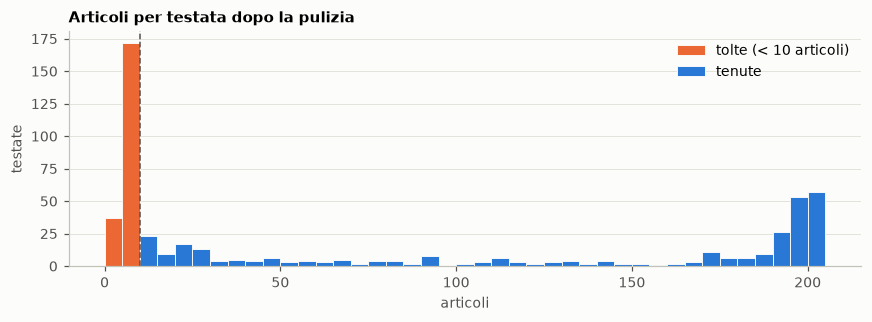

→ restano 42,219 articoli di 323 testate (tolti 1,311 articoli)


In [21]:
# 4.1 almeno 10 articoli per testata
quanti = art.groupby("domain").size()
plt.hist(quanti[quanti < 10], bins=np.arange(0, 210, 5), color=ARANCIO, label="tolte (< 10 articoli)")
plt.hist(quanti[quanti >= 10], bins=np.arange(0, 210, 5), color=BLU, label="tenute"); plt.legend()
plt.axvline(10, color=GRIGIO, ls="--", lw=1)
plt.title("Articoli per testata dopo la pulizia"); plt.xlabel("articoli"); plt.ylabel("testate")
mostra("4_articoli_per_testata")

art = art[art.domain.isin(quanti.index[quanti >= 10])].copy()
passo("4.1 testate con almeno 10 articoli", art)

In [22]:
# 4.2 l'etichetta: il livello dal punteggio NewsGuard 2026 (binario: affidabile se punteggio >= 60, cioè l3–l5)
art["score"] = art.domain.map(n26.Score)
art["label"] = F.livello(art.score)                   # 0..4 = l1..l5
art["livello"] = art.label.map(dict(enumerate(F.LIVELLI)))
pd.DataFrame({"punteggio": ["0–39", "40–59", "60–74", "75–99", "100"], "affidabile": ["no", "no", "sì", "sì", "sì"],
              "testate": art.groupby("livello").domain.nunique(), "articoli": art.groupby("livello").size()}, index=F.LIVELLI)

,punteggio,affidabile,testate,articoli
l1,0–39,no,54,7114
l2,40–59,no,93,12533
l3,60–74,sì,36,4901
l4,75–99,sì,98,11657
l5,100,sì,42,6014


In [23]:
# 4.3 i fold: 5 parti con livelli simili (stratificate), ogni gruppo in una sola parte
t = art.groupby("domain").agg(gruppo=("gruppo", "first"), label=("label", "first"), livello=("livello", "first"),
                              score=("score", "first"), articoli=("article_id", "size"))
t["fold"] = 0
for k, (_, test) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=F.SEED).split(t, t.label, t.gruppo), 1):
    t.iloc[test, t.columns.get_loc("fold")] = k
art["fold"] = art.domain.map(t.fold)
pd.crosstab(t.fold, t.livello, margins=True, margins_name="totale")

livello,l1,l2,l3,l4,l5,totale
fold,,,,,,
1,11,19,8,19,8,65
2,11,19,7,20,8,65
3,11,18,7,20,9,65
4,11,18,7,20,8,64
5,10,19,7,19,9,64
totale,54,93,36,98,42,323


In [24]:
# 4.4 controllo: nessun gruppo è diviso tra due fold
print("✓ ogni gruppo sta in un solo fold" if (t.groupby("gruppo").fold.nunique() == 1).all() else "✗ c'è un gruppo diviso tra fold")

✓ ogni gruppo sta in un solo fold


### Il dataset finale

In [25]:
# 4.5 testate e articoli per livello
finale = pd.DataFrame({"testate": t.livello.value_counts(), "articoli": art.livello.value_counts()}).reindex(F.LIVELLI)
finale.loc["totale"] = finale.sum()
finale.loc["binario: inaffidabili (l1–l2)"] = finale.loc[["l1", "l2"]].sum()
finale.loc["binario: affidabili (l3–l5)"] = finale.loc[["l3", "l4", "l5"]].sum()
finale

,testate,articoli
livello,,
l1,54,7114
l2,93,12533
l3,36,4901
l4,98,11657
l5,42,6014
totale,323,42219
binario: inaffidabili (l1–l2),147,19647
binario: affidabili (l3–l5),176,22572


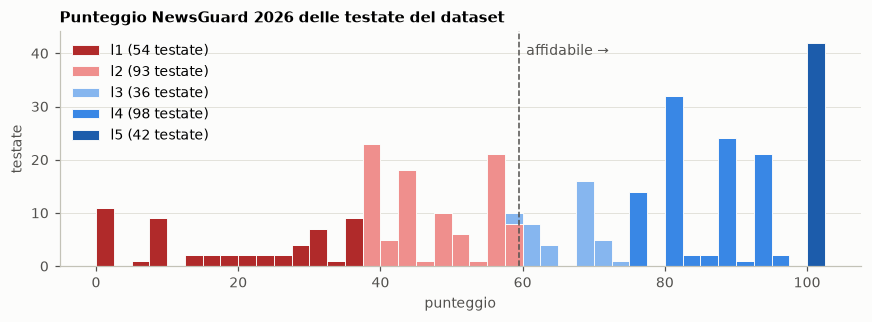

In [26]:
# i punteggi NewsGuard 2026 delle testate del dataset, colorati per livello
plt.hist([t.score[t.label == k] for k in range(5)], np.arange(0, 102.6, 2.5), stacked=True, color=COLORE_LIVELLO,
         label=[f"{l} ({(t.label == k).sum()} testate)" for k, l in enumerate(F.LIVELLI)])
plt.axvline(59.5, color=GRIGIO, ls="--", lw=1); plt.text(60.5, plt.ylim()[1] * 0.9, "affidabile →", color=GRIGIO)
plt.title("Punteggio NewsGuard 2026 delle testate del dataset"); plt.xlabel("punteggio"); plt.ylabel("testate"); plt.legend()
mostra("4_punteggi")

In [27]:
# 4.6 per orientamento politico (NewsGuard 2026)
t["orientamento"] = t.index.map(n26.Orientation).fillna("nessuno")
pd.crosstab(t.orientamento, t.livello, margins=True, margins_name="totale")

livello,l1,l2,l3,l4,l5,totale
orientamento,,,,,,
Left,4,34,6,44,16,104
Right,44,53,23,28,4,152
nessuno,6,6,7,26,22,67
totale,54,93,36,98,42,323


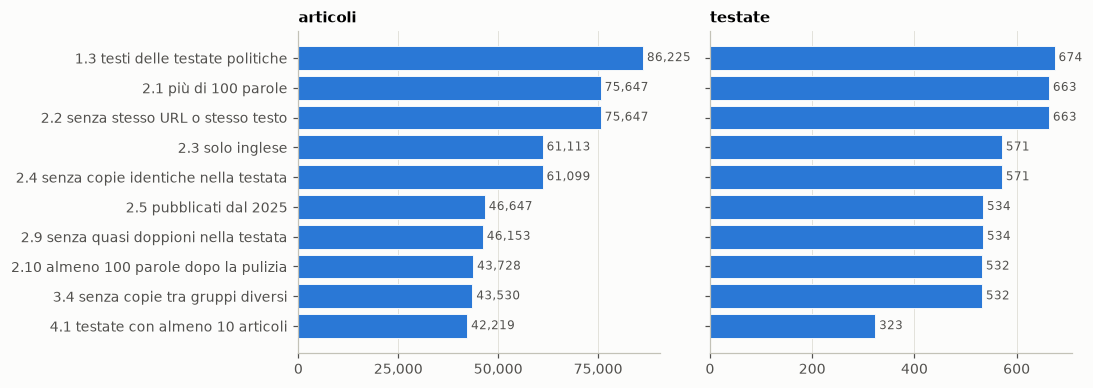

In [28]:
# la pulizia in un colpo d'occhio
p = pd.DataFrame(passi).set_index("passo")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, col in zip(ax, ["articoli", "testate"]):
    a.barh(p.index[::-1], p[col][::-1], color=BLU)
    a.set_title(col); a.xaxis.set_major_formatter("{x:,.0f}"); a.xaxis.set_major_locator(plt.MaxNLocator(4))
    for y, v in enumerate(p[col][::-1]):
        a.text(v, y, f" {v:,}", va="center", fontsize=8, color=GRIGIO)
mostra("4_riassunto", "x")

## 5. Salvo il dataset
Per il notebook di classificazione.

In [29]:
colonne = ["article_id", "domain", "url", "titolo", "data", "text", "label", "gruppo", "fold"]
art[colonne].to_csv(DATASET / "articoli.csv.gz", index=False)
t.to_csv(DATASET / "testate.csv")
print(f"{len(art):,} articoli di {len(t)} testate in {t.gruppo.nunique()} gruppi → {DATASET}/articoli.csv.gz, testate.csv")
pd.DataFrame(passi).set_index("passo")

42,219 articoli di 323 testate in 223 gruppi → Results/dataset/articoli.csv.gz, testate.csv


,articoli,testate
passo,,
1.3 testi delle testate politiche,86225,674
2.1 più di 100 parole,75647,663
2.2 senza stesso URL o stesso testo,75647,663
2.3 solo inglese,61113,571
2.4 senza copie identiche nella testata,61099,571
2.5 pubblicati dal 2025,46647,534
2.9 senza quasi doppioni nella testata,46153,534
2.10 almeno 100 parole dopo la pulizia,43728,532
3.4 senza copie tra gruppi diversi,43530,532
